# Versuch07 – Explorative Datenanalyse

Dieses Notebook untersucht alle Messungen von **Versuch07** entlang der Arbeitspunkte bis Session 2 (01–08).

- **Für einen anderen Versuch `VERSUCH` ändern** (erste Code-Zelle). Der Rest läuft unverändert. Ordner, die mit dem Versuchsnamen beginnen, werden gemeinsam geladen (z. B. `Versuch03_Fairphone` und `Versuch03_iPhone` für `Versuch03`).
- Eine Übersicht aller Messungen (Geräte, Startzeiten, Duplikate) steht in `00_Metadaten_Geraete.ipynb`.

In [1]:
import hashlib, re, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt, find_peaks, welch
warnings.filterwarnings('ignore')   # hide library deprecation warnings so the outputs stay readable

# Path to the raw data – the only line you need to change on another computer
DATA_ROOT = Path('/Users/majasmereczynska/Documents/Industrial AI/IPR_Daten_neu/data/Hybridachse')
# Which Versuch this notebook analyses – change this line to reuse the notebook for another one
VERSUCH = 'Versuch07'

# Figures are saved next to the notebook, prefixed with the Versuch (e.g. V05_...)
FIG = Path('figures'); FIG.mkdir(exist_ok=True)
PREFIX = VERSUCH.replace('Versuch', 'V')

# Plot style: fixed colours in a fixed order (repeat 01 = blue, 02 = orange, 03 = green),
# light grid, no box around the plot
C = ['#2a78d6', '#eb6834', '#1baf7a']
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e4e3df', 'font.size': 9, 'legend.frameon': False})
pd.set_option('display.width', 200, 'display.max_columns', 30)

In [2]:
# Helper functions – used by the sections below

# The two phones name the same sensor file differently (Android 'Linear Acceleration.csv',
# iOS 'Linear Accelerometer.csv'). Map every file name to one short key.
SENSOR = {'Accelerometer': 'acc', 'Linear Acceleration': 'linacc', 'Linear Accelerometer': 'linacc',
          'Gyroscope': 'gyro', 'Magnetometer': 'mag', 'Barometer': 'baro',
          'Location': 'loc', 'Proximity': 'prox'}


def load(folder):
    """Load one recording: device, START/PAUSE events and all sensor tables.
    3-axis sensors get the columns t, x, y, z (the original names differ per phone)."""
    meta = pd.read_csv(folder / 'meta/device.csv').set_index('property')['value']
    # Short display name: 'Versuch04_iPhone_01' -> 'iPhone_01', 'Alle Sensoren 2024-12-09 11-50-01' -> 'iPhone 11-50-01'
    name = re.sub(r'^Versuch\d+_', '', folder.name).replace('Alle Sensoren ', 'iPhone ').replace('2024-12-09 ', '').replace('iPhone iPhone', 'iPhone')
    m = {'name': name, 'dev': 'IP' if 'iPhone' in meta['deviceModel'] else 'FP',
         'device': meta['deviceModel'], 'events': pd.read_csv(folder / 'meta/time.csv'), 'sensors': {}}
    for f in sorted(folder.glob('*.csv')):
        df = pd.read_csv(f)
        if df.shape[1] == 4:                       # time + 3 axes -> unify the column names
            df.columns = ['t', 'x', 'y', 'z']
        else:                                      # e.g. barometer, location: only rename the time column
            df = df.rename(columns={df.columns[0]: 't'})
        m['sensors'][SENSOR[f.stem]] = df
    return m


def load_versuch(versuch):
    """Load all recordings of a Versuch. A recording = a folder that contains meta/time.csv.
    All top-level folders starting with the Versuch name are searched, so 'Versuch03' loads
    both 'Versuch03_Fairphone' and 'Versuch03_iPhone'.
    Byte-identical copies (same Accelerometer.csv) are skipped – some folders in the raw data
    are exported twice; if a copy is mislabelled (folder says Fairphone, data is iPhone),
    the correctly named one is kept."""
    D, seen = {}, {}
    tfs = [tf for top in sorted(DATA_ROOT.glob(versuch + '*')) if top.is_dir() for tf in sorted(top.glob('**/meta/time.csv'))]
    for tf in tfs:
        folder = tf.parent.parent
        m = load(folder)
        h = hashlib.md5((folder / 'Accelerometer.csv').read_bytes()).hexdigest()
        name_ok = ('iphone' in m['name'].lower() or 'ip_' in m['name'].lower()) == (m['dev'] == 'IP')
        if h in seen:
            if name_ok and not seen[h][1]:          # replace the mislabelled copy
                del D[seen[h][0]]
            else:
                print('Duplikat übersprungen:', m['name'])
                continue
        seen[h] = (m['name'], name_ok)
        D[m['name']] = m
    return D


def drive_phases(m):
    """When is the carriage moving? Returns t, vibration envelope and a list of (start, end).
    1. High-pass the linear acceleration at 5 Hz: keeps the drive vibration, removes slow drift.
    2. Rolling median of the magnitude over 0.5 s = smooth 'vibration envelope'
       (median, not mean, so a single jerk is not counted as driving).
    3. 'Moving' = envelope clearly above the quietest 5 % of this recording (3x, at least +0.01 m/s²).
       Relative to each recording, so it works for the noisier Fairphone and the quieter iPhone.
    4. Keep stretches of at least 0.5 s.
    The factors are heuristics – check the grey segments in the overview plot."""
    df = m['sensors']['linacc']
    t, a = df['t'].values, df[['x', 'y', 'z']].values
    fs = 1 / np.median(np.diff(t))
    hp = sosfiltfilt(butter(4, 5, 'hp', fs=fs, output='sos'), a, axis=0)   # forward+backward = no time shift
    env = pd.Series(np.linalg.norm(hp, axis=1)).rolling(int(fs * 0.5), center=True).median().bfill().ffill().values
    quiet = np.percentile(env, 5)
    on = env > max(3 * quiet, quiet + 0.01)
    edges = np.diff(np.r_[0, on.astype(int), 0])          # +1 where a phase starts, -1 where it ends
    starts, ends = np.where(edges == 1)[0], np.where(edges == -1)[0] - 1
    segs = [(t[s], t[e]) for s, e in zip(starts, ends) if t[e] - t[s] >= 0.5]
    return t, env, segs


def impulses(m, thr=2.0):
    """Braking/starting jerks: peaks of |linear acceleration| above thr m/s², at least 0.3 s apart
    (so one jerk with some ringing counts once). Returns peak times and amplitudes."""
    df = m['sensors']['linacc']
    t, am = df['t'].values, np.linalg.norm(df[['x', 'y', 'z']].values, axis=1)
    pk, _ = find_peaks(am, height=thr, distance=int(0.3 / np.median(np.diff(t))))
    return t[pk], am[pk]


def spectrum_drive(m, axis):
    """Frequency spectrum (Welch PSD) of the raw acceleration during steady travel only:
    1 s is cut off both ends of every travel phase, otherwise the start/stop jerks dominate."""
    df = m['sensors']['acc']
    t, fs = df['t'].values, 1 / np.median(np.diff(df['t'].values))
    parts = [df[axis].values[(t > a + 1) & (t < b - 1)] for a, b in drive_phases(m)[2] if b - a > 3]
    if not parts:                                         # carriage never moved -> no spectrum
        return None, None
    x = np.concatenate([p - p.mean() for p in parts])     # remove gravity (mean) of each piece
    return welch(x, fs=fs, nperseg=int(fs * 2))           # 2 s windows -> 0.5 Hz resolution


def main_axis(m):
    """Axis with the most motion – usually y (travel direction) if the phone rides on the carriage."""
    la = m['sensors']['linacc']
    return max('xyz', key=lambda a: la[a].std())

In [3]:
# Load all recordings of this Versuch into a dict: name -> recording
D = load_versuch(VERSUCH)
list(D)

['FP_01']

## 01 Datensatz beschreiben

Welche Messungen, Geräte und Sensordateien gibt es, und wann wurde aufgenommen?

In [4]:
# One row per recording. The absolute start time comes from meta/time.csv: it is the only way to
# see which Fairphone and iPhone recordings ran at the same time. More than 2 START/PAUSE events
# means the recording was paused and restarted.
rows = []
for name, m in D.items():
    ev = m['events']
    rows.append({'Messung': name, 'Gerät': m['device'],
                 'Start (Uhrzeit)': ev['system time text'].iloc[0][11:23],
                 'Dauer (s)': round(ev['experiment time'].iloc[-1], 1),
                 'START/PAUSE-Ereignisse': len(ev),
                 'Sensoren': ', '.join(m['sensors'])})
pd.DataFrame(rows).set_index('Messung')

,Gerät,Start (Uhrzeit),Dauer (s),START/PAUSE-Ereignisse,Sensoren
Messung,,,,,
FP_01,FP4,14:31:29.963,40.3,2,"acc, gyro, linacc, mag"


**Befund 01**

- **1 Messung** mit dem Fairphone (FP_01, Start 14:31:30), Dauer 40 s.
- Keine Unterbrechung, keine Duplikate.

## 02 Messungen charakterisieren

Abtastraten, Zeitstruktur, Wertebereiche und Lage der Handys.

In [5]:
# Sampling rate = 1 / median time step (the median ignores a few long gaps).
# Largest gap = longest time between two samples; reveals pauses or dropped samples.
rows = []
for name, m in D.items():
    for s in ['acc', 'linacc', 'gyro', 'mag']:
        dt = np.diff(m['sensors'][s]['t'].values)
        rows.append({'Messung': name, 'Sensor': s, 'fs (Hz)': round(1 / np.median(dt), 1),
                     'größte Lücke (ms)': round(dt.max() * 1000, 1)})
pd.DataFrame(rows).pivot(index='Messung', columns='Sensor')

fs (Hz)                      größte Lücke (ms)                  
Sensor      acc   gyro linacc    mag               acc gyro linacc   mag
Messung                                                                 
FP_01     426.7  426.7  213.4  100.0               2.4  2.3    4.7  10.0

In [6]:
# Value ranges per device and sensor: smallest minimum and largest maximum over all axes and recordings
rows = []
for name, m in D.items():
    for s, unit in [('acc', 'm/s²'), ('linacc', 'm/s²'), ('gyro', 'rad/s'), ('mag', 'µT')]:
        v = m['sensors'][s][['x', 'y', 'z']]
        rows.append({'Gerät': m['dev'], 'Sensor': f'{s} ({unit})', 'min': v.min().min(), 'max': v.max().max()})
pd.DataFrame(rows).groupby(['Gerät', 'Sensor']).agg({'min': 'min', 'max': 'max'}).round(2)

min    max
Gerät Sensor                     
FP    acc (m/s²)    -37.88  18.95
      gyro (rad/s)   -0.74   0.70
      linacc (m/s²) -34.04  18.55
      mag (µT)      -54.38  19.48

In [7]:
# The phones at rest: samples at least 1 s away from any travel phase.
# - Lage: mean gravity vector (g_x, g_y, g_z) = how the phone lies / is tilted
# - Ruhe-Rauschen: standard deviation of the raw acceleration at rest (mm/s²) = sensor noise
# - Gyro-Offset z: mean rotation rate at rest (should be 0; anything else is sensor bias)
rows = []
for name, m in D.items():
    _, _, segs = drive_phases(m)
    acc, gyro = m['sensors']['acc'], m['sensors']['gyro']
    rest_a = np.ones(len(acc), bool); rest_g = np.ones(len(gyro), bool)
    for a, b in segs:
        rest_a &= ~acc['t'].between(a - 1, b + 1).values
        rest_g &= ~gyro['t'].between(a - 1, b + 1).values
    A = acc[rest_a]
    rows.append({'Messung': name, 'Gerät': m['dev'], 'Ruhe-Samples': int(rest_a.sum()),
                 'g_x': A['x'].mean(), 'g_y': A['y'].mean(), 'g_z': A['z'].mean(),
                 'Ruhe-Rauschen x (mm/s²)': 1000 * A['x'].std(), 'Ruhe-Rauschen y (mm/s²)': 1000 * A['y'].std(),
                 'Ruhe-Rauschen z (mm/s²)': 1000 * A['z'].std(),
                 'Gyro-Offset z (mrad/s)': 1000 * gyro.loc[rest_g, 'z'].mean()})
pd.DataFrame(rows).set_index('Messung').round(3)

,Gerät,Ruhe-Samples,g_x,g_y,g_z,Ruhe-Rauschen x (mm/s²),Ruhe-Rauschen y (mm/s²),Ruhe-Rauschen z (mm/s²),Gyro-Offset z (mrad/s)
Messung,,,,,,,,,
FP_01,FP,15119,-0.136,0.13,-9.952,13.476,12.353,12.537,-0.195


**Befund 02**

- **Abtastraten:** 427 / 213 / 100 Hz. Keine Lücken.
- **Lage:** g ≈ (−0,136, 0,130, −9,95) m/s², also Display unten und leicht geneigt.
- **Ruhe-Rauschen:** 12–13 mm/s².
- **Gyro-Offset z:** −0,2 mrad/s.

## 03 Signale visualisieren

**Abb. 1:** Pro Messung links |lineare Beschleunigung| mit den erkannten Fahrphasen (grau) und Impulsen > 2 m/s² (Punkte), rechts der Betrag des Magnetfelds als grober Positionsindikator.

**Abb. 2:** Frequenzspektrum während der gleichmäßigen Fahrt, je Gerät.

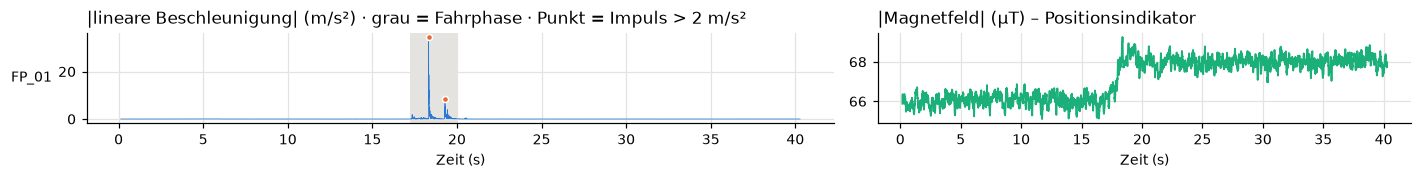

In [8]:
# Fig. 1 – overview, one row per recording, shared time axis
fig, axs = plt.subplots(len(D), 2, figsize=(13, 1.7 * len(D)), sharex=True, squeeze=False,
                        gridspec_kw={'width_ratios': [1.4, 1]})
for i, (name, m) in enumerate(D.items()):
    la = m['sensors']['linacc']
    t, env, segs = drive_phases(m)
    for a, b in segs:                                           # grey = detected travel phase
        axs[i, 0].axvspan(a, b, color='#e4e3df', lw=0)
    axs[i, 0].plot(la['t'], np.linalg.norm(la[['x', 'y', 'z']].values, axis=1), color=C[0], lw=0.5)
    pt, pa = impulses(m)
    axs[i, 0].plot(pt, pa, 'o', ms=4, color=C[1], mec='white')  # orange dots = impulses
    axs[i, 0].set_ylabel(name, rotation=0, ha='right', va='center')
    mg = m['sensors']['mag']                                    # magnetic field magnitude = position proxy
    axs[i, 1].plot(mg['t'], np.linalg.norm(mg[['x', 'y', 'z']].values, axis=1), color=C[2], lw=1.2)
axs[0, 0].set_title('|lineare Beschleunigung| (m/s²) · grau = Fahrphase · Punkt = Impuls > 2 m/s²', loc='left')
axs[0, 1].set_title('|Magnetfeld| (µT) – Positionsindikator', loc='left')
for ax in axs[-1]:
    ax.set_xlabel('Zeit (s)')
fig.tight_layout(); fig.savefig(FIG / f'{PREFIX}_1_uebersicht.png', dpi=150)

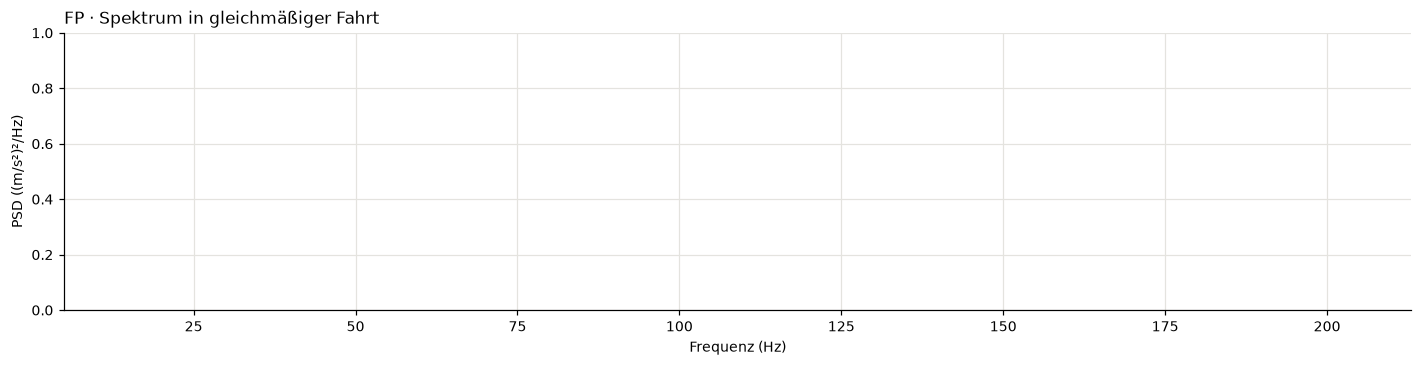

In [9]:
# Fig. 2 – spectrum during steady travel, one panel per device (Fairphone samples at 427 Hz,
# iPhone at 100 Hz, so their frequency ranges differ and must not share one axis).
# Each recording is shown on its main axis. Log scale: spectral lines stand out by orders of magnitude.
devs = sorted({m['dev'] for m in D.values()})
fig, axs = plt.subplots(1, len(devs), figsize=(13 if len(devs) == 1 else 15, 3.4), squeeze=False)
for ax, dev in zip(axs[0], devs):
    for i, (name, m) in enumerate((n, m) for n, m in D.items() if m['dev'] == dev):
        ax_name = main_axis(m)
        f, P = spectrum_drive(m, ax_name)
        if f is None:                                         # no travel phase -> nothing to plot
            continue
        ax.semilogy(f, P, color=C[i % 3], lw=1, label=f'{name} · {ax_name}')
    ax.set_xlim(5, 213 if dev == 'FP' else 50); ax.set_xlabel('Frequenz (Hz)'); ax.legend(fontsize=8)
    ax.set_title(f'{dev} · Spektrum in gleichmäßiger Fahrt', loc='left')
axs[0, 0].set_ylabel('PSD ((m/s²)²/Hz)')
fig.tight_layout(); fig.savefig(FIG / f'{PREFIX}_2_spektrum.png', dpi=150)

**Befund 03**

- **Abb. 1:** Fast die ganze Messung ist **Ruhe**. Nur zwischen ≈ 17 und 20 s gibt es kurze Aktivität mit einem sehr starken Ruck (**34,6 m/s²**). Gleichzeitig springt das Magnetfeld dauerhaft um ≈ 2 µT (66 → 68 µT).
- **Kein Fahrprofil:** Es gibt keine Hin- und Rückfahrt.
- *Interpretation:* Das Handy wurde *vermutlich* **angestoßen oder umgelegt**. Ein Fahrversuch ist in den Daten nicht zu sehen.
- **Abb. 2:** kein Spektrum berechenbar (keine Fahrphase über 3 s).

## 04 Messungen vergleichen

Für jede Messung dieselben acht Kennzahlen (Merkmale), damit die Wiederholungen direkt vergleichbar sind.

In [10]:
# Features per recording:
# - Fahrzeit: total time the carriage moves; Fahrabschnitte: travel phases > 2 s
#   (2 = continuous out and back, more = stops in between)
# - Fahr-Vibration: median of the vibration envelope while moving
# - Impulse / max |a|: number and strength of the braking/starting jerks
# - dominante Frequenz: strongest spectral peak above 20 Hz during steady travel
#   (below 20 Hz is the slow motion of the carriage itself)
# - |B|-Spanne: range of the magnetic field = how far the phone moves past steel parts
rows = []
for name, m in D.items():
    t, env, segs = drive_phases(m)
    moving = np.zeros(len(t), bool)
    for a, b in segs:
        moving |= (t >= a) & (t <= b)
    pt, pa = impulses(m)
    f, P = spectrum_drive(m, main_axis(m))
    dom = round(f[f > 20][P[f > 20].argmax()], 1) if f is not None else np.nan
    mg = m['sensors']['mag']; B = np.linalg.norm(mg[['x', 'y', 'z']].values, axis=1)
    la = m['sensors']['linacc']
    rows.append({'Messung': name, 'Gerät': m['dev'],
                 'Dauer (s)': round(t[-1], 1),
                 'Fahrzeit (s)': round(moving.mean() * t[-1], 1),
                 'Fahrabschnitte': sum(b - a > 2 for a, b in segs),
                 'Fahr-Vibration (m/s²)': round(np.median(env[moving]), 3) if moving.any() else np.nan,
                 'Impulse > 2 m/s²': len(pt),
                 'max |a| (m/s²)': round(np.linalg.norm(la[['x', 'y', 'z']].values, axis=1).max(), 1),
                 'dominante Frequenz (Hz)': dom,
                 '|B|-Spanne (µT)': round(B.max() - B.min(), 1)})
feat = pd.DataFrame(rows).set_index('Messung')
feat

,Gerät,Dauer (s),Fahrzeit (s),Fahrabschnitte,Fahr-Vibration (m/s²),Impulse > 2 m/s²,max |a| (m/s²),dominante Frequenz (Hz),|B|-Spanne (µT)
Messung,,,,,,,,,
FP_01,FP,40.3,2.8,1,0.148,2,34.6,NaN,4.2


**Befund 04**

- **Fahrzeit:** 2,8 s, 1 erkannter Abschnitt (die Aktivität um 17–20 s).
- **Impulse:** 2, max |a| 34,6 m/s².
- **|B|-Spanne:** 4,2 µT.
- Die Merkmale beschreiben **keine Fahrt**.

## 05 Datenqualität prüfen

Fehlende Werte, konstante Spalten, doppelte Zeitstempel und Aufnahmepausen.

In [11]:
# Check every file; only files with a problem are shown
rows = []
for name, m in D.items():
    for s, df in m['sensors'].items():
        num = df.drop(columns='t')
        rows.append({'Messung': name, 'Sensor': s, 'Zeilen': len(df),
                     'fehlende Werte': int(num.isna().sum().sum()),
                     'konstante Spalten': ', '.join(c for c in num if num[c].nunique() <= 1),   # no information
                     'doppelte Zeitstempel': int(df['t'].duplicated().sum())})
q = pd.DataFrame(rows)
q[(q['fehlende Werte'] > 0) | (q['konstante Spalten'] != '') | (q['Zeilen'] < 10) | (q['doppelte Zeitstempel'] > 0)]

,Messung,Sensor,Zeilen,fehlende Werte,konstante Spalten,doppelte Zeitstempel


In [12]:
# Recordings that were paused and restarted (more than one START/PAUSE pair) -> time gap in the data
for name, m in D.items():
    if len(m['events']) > 2:
        print(name); print(m['events'][['event', 'experiment time', 'system time text']].to_string(index=False))

**Befund 05**

- Keine fehlenden Werte, keine Lücken, keine Pausen.
- Der Ruck von 34,6 m/s² ist *vermutlich* **Handhabung**, kein Messfehler.

## 06 Normalverhalten charakterisieren

Wie ähnlich sind die Wiederholungen? Grundlage: Mittelwert und Variationskoeffizient (CV = Standardabweichung / Mittelwert) der Merkmale sowie die Vibrationshüllkurven, ausgerichtet auf die erste Bewegung (**Abb. 3**).

In [13]:
# Small CV (a few %) = repeats behave the same = stable reference for 'normal'
cols = ['Fahrzeit (s)', 'Fahrabschnitte', 'Fahr-Vibration (m/s²)', 'Impulse > 2 m/s²', 'max |a| (m/s²)', '|B|-Spanne (µT)']
g = feat.groupby('Gerät')[cols]
pd.concat({'Mittelwert': g.mean().round(3), 'CV (%)': (100 * g.std() / g.mean()).round(1)}, axis=1).T

Gerät                                 FP
Mittelwert Fahrzeit (s)            2.800
           Fahrabschnitte          1.000
           Fahr-Vibration (m/s²)   0.148
           Impulse > 2 m/s²        2.000
           max |a| (m/s²)         34.600
           |B|-Spanne (µT)         4.200
CV (%)     Fahrzeit (s)              NaN
           Fahrabschnitte            NaN
           Fahr-Vibration (m/s²)     NaN
           Impulse > 2 m/s²          NaN
           max |a| (m/s²)            NaN
           |B|-Spanne (µT)           NaN

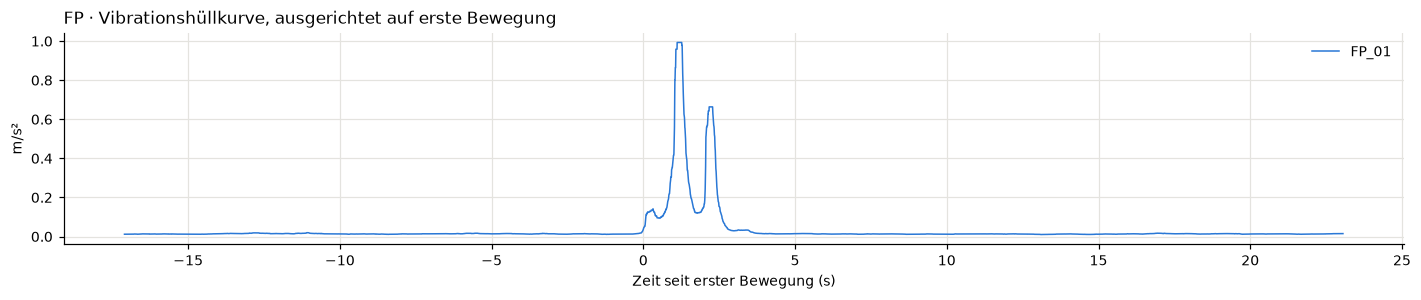

In [14]:
# Fig. 3 – vibration envelopes of the repeats, one panel per device. Shifted so t = 0 is the first
# movement: recordings start at different times before the carriage moves, so comparing on
# recording time would hide how similar the repeats are.
fig, axs = plt.subplots(len(devs), 1, figsize=(13, 2.8 * len(devs)), sharex=True, squeeze=False)
for ax, dev in zip(axs[:, 0], devs):
    for i, (name, m) in enumerate((n, m) for n, m in D.items() if m['dev'] == dev):
        t, env, segs = drive_phases(m)
        t0 = segs[0][0] if segs else 0               # no movement: keep the recording time
        ax.plot(t - t0, env, color=C[i % 3], lw=1, label=name)
    ax.set_title(f'{dev} · Vibrationshüllkurve, ausgerichtet auf erste Bewegung', loc='left')
    ax.set_ylabel('m/s²'); ax.legend(loc='upper right')
axs[-1, 0].set_xlabel('Zeit seit erster Bewegung (s)')
fig.tight_layout(); fig.savefig(FIG / f'{PREFIX}_3_normalverhalten.png', dpi=150)

**Befund 06**

- Nur eine Messung, deshalb keine Aussage über Wiederholbarkeit möglich.
- **Fazit:** Versuch07 enthält **keine auswertbare Fahrt**. Bis zur Klärung sollte er nicht als Referenz und nicht als Anomalie verwendet werden.

## 07 Hypothesen

- **H1:** Versuch07 ist ein abgebrochener oder fehlgeschlagener Versuch.
  - *Test:* Versuchsprotokoll prüfen. Lage vor und nach dem Ruck vergleichen (Magnetfeld-Sprung deutet auf Verschieben des Handys).

## 08 Offene Fragen

- Was sollte in Versuch07 gemessen werden?
- Warum fehlt die Fahrt?